## Let's generate music with RNN

In [2]:

# Install required packages
%pip install mitdeeplearning numpy scipy tqdm matplotlib

# Import PyTorch and other libraries
import torch
import torch.nn as nn
import torch.optim as optim

import numpy as np
import os
import time
import functools

from IPython import display as ipythondisplay
from tqdm import tqdm
from scipy.io.wavfile import write

# Select CPU
device = torch.device("cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)
print("Environment setup completed successfully!")



  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [23 lines of output]
      Traceback (most recent call last):
        File "c:\Users\sahil\AppData\Local\Programs\Python\Python313\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 389, in <module>
          main()
          ~~~~^^
        File "c:\Users\sahil\AppData\Local\Programs\Python\Python313\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 373, in main
          json_out["return_val"] = hook(**hook_input["kwargs"])
                                   ~~~~^^^^^^^^^^^^^^^^^^^^^^^^
        File "c:\Users\sahil\AppData\Local\Programs\Python\Python313\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 143, in get_requires_for_build_wheel
          return hook(config_settings)
        File "C:\Users\sahil\AppData\Local\Temp\pip-build-env-mc0s7t18\overlay\Lib\site-packa

  Using cached mitdeeplearning-0.7.5.tar.gz (2.8 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'
Note: you may need to restart the kernel to use updated packages.
PyTorch version: 2.14.1+cpu
Device: cpu
Environment setup completed successfully!


In [3]:
import sys
import os

repo_path = r"D:\guar dai\AI-ML-Projects\introtodeeplearning"

print("Repository exists:", os.path.exists(repo_path))
print("Package exists:", os.path.exists(
    os.path.join(repo_path, "mitdeeplearning")
))

sys.path.insert(0, repo_path)

print("MIT package imported successfully!")

Repository exists: False
Package exists: False
MIT package imported successfully!


# Importing the dataset


In [4]:
from pathlib import Path

data_path = Path("data/irish.abc")


In [5]:
# Read the dataset 

with open(data_path , "r" , encoding = "utf-8") as file:
    text = file.read()

print("Dataset loaded successfully!")
print("Total characters:", len(text))

Dataset loaded successfully!
Total characters: 197618


In [6]:
print("\nFirst 1000 characters:\n")
print(text[:1000])


First 1000 characters:

X:1
T:Alexander's
Z: id:dc-hornpipe-1
M:C|
L:1/8
K:D Major
(3ABc|dAFA DFAd|fdcd FAdf|gfge fefd|(3efe (3dcB A2 (3ABc|!
dAFA DFAd|fdcd FAdf|gfge fefd|(3efe dc d2:|!
AG|FAdA FAdA|GBdB GBdB|Acec Acec|dfaf gecA|!
FAdA FAdA|GBdB GBdB|Aceg fefd|(3efe dc d2:|!

X:2
T:An Buachaill Dreoite
Z: id:dc-hornpipe-2
M:C|
L:1/8
K:G Major
GF|DGGB d2GB|d2GF Gc (3AGF|DGGB d2GB|dBcA F2GF|!
DGGB d2GF|DGGF G2Ge|fgaf gbag|fdcA G2:|!
GA|B2BG c2cA|d2GF G2GA|B2BG c2cA|d2DE F2GA|!
B2BG c2cA|d^cde f2 (3def|g2gf gbag|fdcA G2:|!

X:3
T:Belfast
Z: id:dc-hornpipe-3
M:C|
L:1/8
K:D Major
ag|(3faf df AdFA|DFAd f2ef|gbec dfAF|GABG E2ag|!
(3faf df AdFA|DFAd f2ef|gbed cABc|d2f2 d2:|!
(3DEF|GFGA Bcde|fgfe dcdB|A2f2 fef2|G2e2 ede2|!
GFGA Bcde|fgfe dcdB|Afed cABc|d2f2 d2:|!
ag|(3fgf (3efe (3ded (3cdc|(3BcB (3ABA G2ba|(3gag (3fgf (3efe (3ded|(3cdc (3BcB A2ag|!
(3fgf (3efe (3ded (3cdc|(3BcB (3ABA (3GAG (3FGF|Eged cABc|d2f2 d2:|!

X:4
T:Blackbird
Z: id:dc-hornpipe-4
M:C|
L:1/8
K:D Mixolydian
AG|F2FA GFD2|d

In [7]:
print("Data type:" , type(text))
print("Total characters:" , len(text))
print("Number of lines:" , len(text.splitlines()))
print("Unique characters:" , len(set(text)))




Data type: <class 'str'>
Total characters: 197618
Number of lines: 9301
Unique characters: 83


In [8]:
# Converting the ABC notation to audio file and listening to it 

# Split dataset into individual songs
songs = text.split("\n\n")


first_song = next(
    song for song in songs if "X:" in song and "K:" in song
)

print(first_song)

X:1
T:Alexander's
Z: id:dc-hornpipe-1
M:C|
L:1/8
K:D Major
(3ABc|dAFA DFAd|fdcd FAdf|gfge fefd|(3efe (3dcB A2 (3ABc|!
dAFA DFAd|fdcd FAdf|gfge fefd|(3efe dc d2:|!
AG|FAdA FAdA|GBdB GBdB|Acec Acec|dfaf gecA|!
FAdA FAdA|GBdB GBdB|Aceg fefd|(3efe dc d2:|!


In [9]:
output_path = Path("data/first_song.abc")
output_path.write_text(first_song.strip() + "\n", encoding="utf-8")

print("Saved:", output_path)

Saved: data\first_song.abc


Dataset loaded!
Total characters: 197618
Total lines: 9301
Total songs: 804

First song:

X:1
T:Alexander's
Z: id:dc-hornpipe-1
M:C|
L:1/8
K:D Major
(3ABc|dAFA DFAd|fdcd FAdf|gfge fefd|(3efe (3dcB A2 (3ABc|!
dAFA DFAd|fdcd FAdf|gfge fefd|(3efe dc d2:|!
AG|FAdA FAdA|GBdB GBdB|Acec Acec|dfaf gecA|!
FAdA FAdA|GBdB GBdB|Aceg fefd|(3efe dc d2:|!



Total songs: 804
Total characters: 197618
Average song length: 243.77985074626866
Longest song: 603
Shortest song: 142





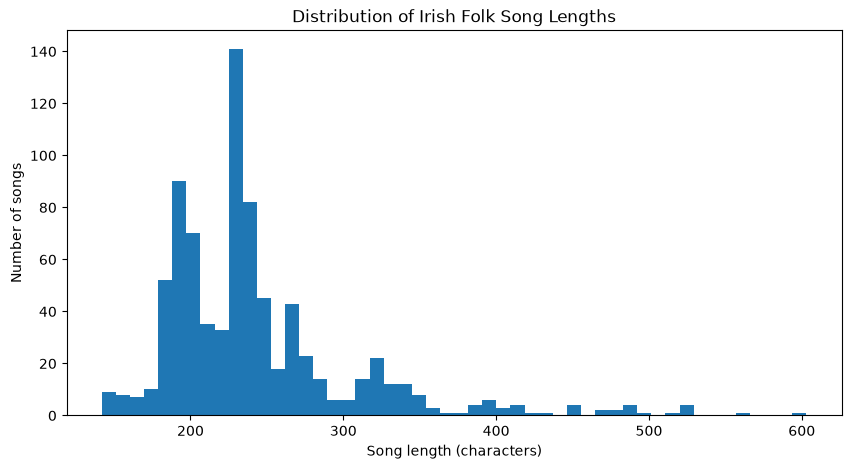

In [10]:
from pathlib import Path

# Load complete dataset
data_path = Path("data/irish.abc")

with open(data_path, "r", encoding="utf-8") as f:
    raw_data = f.read()

print("Dataset loaded!")
print("Total characters:", len(raw_data))
print("Total lines:", len(raw_data.splitlines()))

import re

# Split whenever a new tune begins with X:
songs = re.split(r"(?m)(?=^X:\s*)", raw_data)

# Remove empty entries
songs = [song.strip() for song in songs if song.strip()]

print("Total songs:", len(songs))
print("\nFirst song:\n")
print(songs[0])


print("\n\n")


# Calculate dataset statistics
song_lengths = [len(song) for song in songs]

print("Total songs:", len(songs))
print("Total characters:", len(raw_data))
print("Average song length:", sum(song_lengths) / len(song_lengths))
print("Longest song:", max(song_lengths))
print("Shortest song:", min(song_lengths))

print("\n\n")

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(song_lengths, bins=50)

plt.xlabel("Song length (characters)")
plt.ylabel("Number of songs")
plt.title("Distribution of Irish Folk Song Lengths")

plt.show()

### Convert text to numbers 

In [11]:
# Extract all unique characters
vocab = sorted(set(raw_data))

# Vocabulary size
vocab_size = len(vocab)

In [12]:
print("Vocabulary size:", vocab_size)
print("\nUnique characters:")
print(vocab)

Vocabulary size: 83

Unique characters:
['\n', ' ', '!', '"', '#', "'", '(', ')', ',', '-', '.', '/', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', ':', '<', '=', '>', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', '[', ']', '^', '_', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', '|']


Assign a numerical ID to each character

In [13]:
# Character to integer mapping 

char2idx = { char: idx for idx , char in enumerate(vocab)}

In [14]:
# Integer to character mapping
idx2char = {
    idx: char for idx, char in enumerate(vocab)
}


In [15]:
print("Character to index:")
print(char2idx)

print("\nIndex to character:")
print(idx2char)

Character to index:
{'\n': 0, ' ': 1, '!': 2, '"': 3, '#': 4, "'": 5, '(': 6, ')': 7, ',': 8, '-': 9, '.': 10, '/': 11, '0': 12, '1': 13, '2': 14, '3': 15, '4': 16, '5': 17, '6': 18, '7': 19, '8': 20, '9': 21, ':': 22, '<': 23, '=': 24, '>': 25, 'A': 26, 'B': 27, 'C': 28, 'D': 29, 'E': 30, 'F': 31, 'G': 32, 'H': 33, 'I': 34, 'J': 35, 'K': 36, 'L': 37, 'M': 38, 'N': 39, 'O': 40, 'P': 41, 'Q': 42, 'R': 43, 'S': 44, 'T': 45, 'U': 46, 'V': 47, 'W': 48, 'X': 49, 'Y': 50, 'Z': 51, '[': 52, ']': 53, '^': 54, '_': 55, 'a': 56, 'b': 57, 'c': 58, 'd': 59, 'e': 60, 'f': 61, 'g': 62, 'h': 63, 'i': 64, 'j': 65, 'k': 66, 'l': 67, 'm': 68, 'n': 69, 'o': 70, 'p': 71, 'q': 72, 'r': 73, 's': 74, 't': 75, 'u': 76, 'v': 77, 'w': 78, 'x': 79, 'y': 80, 'z': 81, '|': 82}

Index to character:
{0: '\n', 1: ' ', 2: '!', 3: '"', 4: '#', 5: "'", 6: '(', 7: ')', 8: ',', 9: '-', 10: '.', 11: '/', 12: '0', 13: '1', 14: '2', 15: '3', 16: '4', 17: '5', 18: '6', 19: '7', 20: '8', 21: '9', 22: ':', 23: '<', 24: '=', 25:

Convert the entire dataset into numbers

In [16]:
import numpy as np


In [17]:
encoded_data = np.array([char2idx[char] for char in raw_data] , dtype= np.int64)

print("Original data:", raw_data[:50])
print("Encoded data:", encoded_data[:50])

Original data: X:1
T:Alexander's
Z: id:dc-hornpipe-1
M:C|
L:1/8
K
Encoded data: [49 22 13  0 45 22 26 67 60 79 56 69 59 60 73  5 74  0 51 22  1 64 59 22
 59 58  9 63 70 73 69 71 64 71 60  9 13  0 38 22 28 82  0 37 22 13 11 20
  0 36]


In [18]:

print("Original data:", raw_data[:50])
print("Encoded data:", encoded_data[:50])

print("\nEncoded data shape:", encoded_data.shape)
print("Data type:", encoded_data.dtype)

Original data: X:1
T:Alexander's
Z: id:dc-hornpipe-1
M:C|
L:1/8
K
Encoded data: [49 22 13  0 45 22 26 67 60 79 56 69 59 60 73  5 74  0 51 22  1 64 59 22
 59 58  9 63 70 73 69 71 64 71 60  9 13  0 38 22 28 82  0 37 22 13 11 20
  0 36]

Encoded data shape: (197618,)
Data type: int64


Decode it back into text

In [19]:
# Decode first 100 characters
decoded_text = ''.join(
    idx2char[int(idx)] for idx in encoded_data[:100]
)

print(decoded_text)

print("\n")

print(raw_data[:100])

X:1
T:Alexander's
Z: id:dc-hornpipe-1
M:C|
L:1/8
K:D Major
(3ABc|dAFA DFAd|fdcd FAdf|gfge fefd|(3efe


X:1
T:Alexander's
Z: id:dc-hornpipe-1
M:C|
L:1/8
K:D Major
(3ABc|dAFA DFAd|fdcd FAdf|gfge fefd|(3efe


Sequence Generation and Batching.

In [21]:
import torch 
import numpy as np 

data_tensor = torch.tensor(
    encoded_data , dtype = torch.long
)

print("Dataset shape:", data_tensor.shape)
print("Dataset type:", data_tensor.dtype)

Dataset shape: torch.Size([197618])
Dataset type: torch.int64


In [23]:
def get_batch(data , batch_size , seq_length):

    idx = torch.randint( 0 , len(data) - seq_length-1,
(batch_size,) )

    x = [ data[i:i+seq_length] for i in idx]

    y = [ data [ i+1 : i + seq_length + 1 ] for i in idx]

    x = torch.stack(x)
    y = torch.stack(y)

    return x , y

In [24]:
x , y = get_batch( data_tensor , 4 , 10)

print("Input shape " , x.shape)
print("Input shape " , y.shape)



Input shape  torch.Size([4, 10])
Input shape  torch.Size([4, 10])


Building the LSTM architecture

In [ ]:
# import torch
# import torch.nn as nn

# embedding = nn.Embedding(
#     num_embeddings=5,
#     embedding_dim=4
# )

# notes = torch.tensor([0, 1, 2, 3, 4])

# result = embedding(notes)

# print(result)
# print("Shape:", result.shape)

tensor([[ 0.9578, -1.1117, -1.6818,  0.0662],
        [-0.7892, -0.5203, -0.1395,  2.3241],
        [ 0.3604, -1.2256,  0.2633, -0.8217],
        [-0.1637,  0.3867, -0.3574, -0.0624],
        [ 1.8889,  1.0411,  1.8799, -0.6201]], grad_fn=<EmbeddingBackward0>)
Shape: torch.Size([5, 4])


In [26]:
vocab_size = len(vocab)
embedding_dim = 64
hidden_size = 128